# 딥러닝 기반 금속 표면 불량 유형 분류 시스템

금속 표면 이미지의 결함 유형을 분류하는 CNN 모델을 만들고, 판단 근거를 시각화하여 Streamlit 웹앱으로 제공하는 프로젝트입니다.

- **데이터셋:** NEU Surface Defect Database
- **분류 대상:** crazing(균열), inclusion(개재물), patches(반점), pitted surface(패임), rolled-in scale(압연 스케일), scratches(긁힘)의 6종
- **사용 기술:** Python, TensorFlow/Keras, NumPy, Pandas, Matplotlib, Seaborn, Pillow, scikit-learn, Jupyter Notebook, Streamlit, GitHub, SourceTree

## 1단계: 개발 환경 점검

라이브러리 설치 버전, Python 실행 환경, TensorFlow 장치 인식 및 프로젝트 폴더의 존재 여부를 확인합니다.


In [5]:
# 설치된 패키지의 버전 조회와 미설치 예외 처리를 불러옴
from importlib.metadata import PackageNotFoundError, version

# 딥러닝 모델 구성용 TensorFlow와 Keras를 불러옴
import tensorflow as tf
from tensorflow import keras
# 배열 계산과 표 형태 데이터 처리용 라이브러리를 불러옴
import numpy as np
import pandas as pd
# 그래프 작성과 통계 시각화용 라이브러리를 불러옴
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
# 이미지 처리와 머신러닝 분석용 라이브러리를 불러옴
import PIL
from PIL import Image
import sklearn

# 불러온 라이브러리의 설치 버전을 출력함
print("TensorFlow:", tf.__version__)
print("Keras (tensorflow.keras):", version("keras"))
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Pillow:", PIL.__version__)
print("scikit-learn:", sklearn.__version__)
print("위 라이브러리 import 완료")

# Streamlit 웹앱 실행 없이 설치 버전만 조회함
try:
    print("Streamlit:", version("streamlit"))
# Streamlit이 없으면 미설치 상태를 출력함
except PackageNotFoundError:
    print("Streamlit: 미설치 (선택한 커널 환경에 설치가 필요합니다.)")


TensorFlow: 2.21.0
Keras (tensorflow.keras): 3.15.1
NumPy: 2.5.4
Pandas: 3.1.0
Matplotlib: 3.11.2
Seaborn: 0.13.2
Pillow: 13.0.0
scikit-learn: 1.9.1
위 라이브러리 import 완료
Streamlit: 1.66.1


In [7]:
# Python 정보, 경로 처리, TensorFlow 장치 조회 기능을 불러옴
import sys
from pathlib import Path
import tensorflow as tf

# 현재 Notebook 커널의 Python 버전과 실행 파일 경로를 출력함
print("Python 버전:", sys.version)
print("Python 실행 경로:", sys.executable)
# TensorFlow 버전과 인식된 GPU 및 CPU 목록을 출력함
print("TensorFlow 버전:", tf.__version__)


Python 버전: 3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]
Python 실행 경로: d:\metal-surface-defect\.venv\Scripts\python.exe
TensorFlow 버전: 2.21.0


## 2단계: NEU 데이터셋 확보 및 확인

원본 데이터의 폴더 구조, 클래스별 이미지 수, 이미지 크기와 채널, 정상 열림 여부를 확인합니다. 검사 중 원본 데이터는 변경하지 않습니다.

### 데이터셋 출처와 확인 기준

- 제공: Northeastern University(중국 동북대학교), Kechen Song / Yunhui Yan
- [공식 NEU Surface Defect Database 안내 및 다운로드](https://faculty.neu.edu.cn/songkc/en/zdylm/263265/list/)
- [공식 안내 페이지의 NEU-CLS 다운로드 링크(Google Drive)](https://drive.google.com/file/d/1NGlXT9sIaQpyxUoT6MLKm1Pr6x8oxOvc/view)
- 선택할 자료: 이미지 분류용 **NEU-CLS**. NEU-DET(검출용), NEU-CLS-64(64×64)와 구분합니다.
- 공식 기준: **6개 클래스, 클래스별 300장, 총 1,800장, 200×200 픽셀, 흑백**
- 클래스: Cr = crazing(균열), In = inclusion(개재물), Pa = patches(반점), PS = pitted surface(패임), RS = rolled-in scale(압연 스케일), Sc = scratches(긁힘)
- 현재 확인한 배치: `D:/metal-surface-defect/data/NEU/NEU-CLS/Cr_1.bmp` 형태로 한 폴더에 이미지가 있습니다. 별도 클래스 폴더를 만들지 않고 파일명 접두어로 구분합니다.

각 목록은 처음 일부만 출력하며 전체 검사 결과는 해당 변수에 보관합니다.


In [9]:
# 데이터 경로 처리를 위한 Path를 불러옴
from pathlib import Path

# 프로젝트와 NEU 데이터셋의 절대 경로를 지정함
project_dir_step2 = Path("D:/metal-surface-defect")
neu_dir = project_dir_step2 / "data" / "NEU"
# 현재 작업 위치와 실제 검사 대상 경로를 출력함
print("현재 작업 디렉터리:", Path.cwd())
print("프로젝트 경로:", project_dir_step2)
print("데이터 경로:", neu_dir)

# 프로젝트 또는 데이터 폴더가 없으면 원인을 포함한 오류를 발생시킴
if not project_dir_step2.is_dir():
    raise FileNotFoundError(f"프로젝트 폴더가 없습니다. 드라이브와 경로를 확인하세요: {project_dir_step2}")
if not neu_dir.is_dir():
    raise FileNotFoundError(f"data/NEU 폴더가 없습니다. 압축 해제 위치를 확인하세요: {neu_dir}")

# 하위 경로를 재귀 탐색하고 폴더와 파일을 구분함
neu_entries = sorted(neu_dir.rglob("*"))
neu_folders = [path for path in neu_entries if path.is_dir()]
neu_files = [path for path in neu_entries if path.is_file()]
# 탐색한 폴더 및 파일 개수와 하위 폴더 최대 30개를 출력함
print(f"하위 폴더 {len(neu_folders)}개 / 전체 파일 {len(neu_files)}개")
print("[폴더 구조: 최대 30개]")
print("data/NEU/")
for path in neu_folders[:30]:
    print("  " + path.relative_to(neu_dir).as_posix() + "/")
# 파일의 상대 경로 예시를 최대 10개 출력함
print("[파일 경로 예시: 최대 10개]")
for path in neu_files[:10]:
    print(" ", path.relative_to(neu_dir).as_posix())
# 파일이 없으면 압축 해제 위치 확인 메시지를 출력함
if not neu_files:
    print("주의: 파일이 없습니다. NEU-CLS 압축 파일을 이 경로 아래에 해제했는지 확인하세요.")


현재 작업 디렉터리: d:\metal-surface-defect
프로젝트 경로: D:\metal-surface-defect
데이터 경로: D:\metal-surface-defect\data\NEU
하위 폴더 1개 / 전체 파일 1801개
[폴더 구조: 최대 30개]
data/NEU/
  NEU-CLS/
[파일 경로 예시: 최대 10개]
  NEU-CLS/Cr_1.bmp
  NEU-CLS/Cr_10.bmp
  NEU-CLS/Cr_100.bmp
  NEU-CLS/Cr_101.bmp
  NEU-CLS/Cr_102.bmp
  NEU-CLS/Cr_103.bmp
  NEU-CLS/Cr_104.bmp
  NEU-CLS/Cr_105.bmp
  NEU-CLS/Cr_106.bmp
  NEU-CLS/Cr_107.bmp


In [10]:
# 파일명 분석용 정규식과 개수 집계용 Counter를 불러옴
import re
from collections import Counter

# 파일명 접두어와 6개 결함 클래스의 대응 관계를 지정함
class_names = {
    "cr": "crazing (균열)",
    "in": "inclusion (개재물)",
    "pa": "patches (반점)",
    "ps": "pitted surface (패임)",
    "rs": "rolled-in scale (압연 스케일)",
    "sc": "scratches (긁힘)",
}
# 확장자로 이미지 파일과 이미지 이외 파일을 구분함
image_extensions = {".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff", ".gif", ".webp"}
image_paths = [path for path in neu_files if path.suffix.lower() in image_extensions]
other_paths = [path for path in neu_files if path.suffix.lower() not in image_extensions]
# 클래스별 개수와 번호 및 분류 불가 파일 저장 공간을 초기화함
class_counts = Counter({prefix: 0 for prefix in class_names})
class_numbers = {prefix: [] for prefix in class_names}
unknown_paths = []

# 각 이미지 파일명에서 클래스 접두어와 일련번호를 추출함
for path in image_paths:
    match = re.fullmatch(r"([A-Za-z]+)_(\d+)", path.stem)
    # 파일명 형식이나 접두어가 맞지 않으면 별도 목록에 저장함
    if match is None or match.group(1).lower() not in class_names:
        unknown_paths.append(path)
        continue
    # 접두어 대소문자를 통일하고 클래스 개수와 번호를 누적함
    prefix = match.group(1).lower()
    class_counts[prefix] += 1
    class_numbers[prefix].append(int(match.group(2)))

# 이미지가 저장된 실제 폴더 경로를 출력함
print("이미지가 발견된 폴더:")
for folder in sorted({path.parent for path in image_paths}):
    print(" ", folder.relative_to(neu_dir).as_posix())
# 클래스별 이미지 수를 기대값 300장과 비교하여 출력함
for prefix, name in class_names.items():
    count = class_counts[prefix]
    print(f"{prefix.upper():2} | {name}: {count}장 / 기대 300장 -> {'정상' if count == 300 else '확인 필요'}")
# 확인된 클래스 수와 전체 및 분류 불가 파일 수를 출력함
print(f"확인된 클래스: {sum(count > 0 for count in class_counts.values())}개 / 기대 6개")
print(f"전체 이미지: {len(image_paths)}장 / 기대 1800장")
print(f"분류 불가 파일: {len(unknown_paths)}개 / 이미지 이외 파일: {len(other_paths)}개")
# 분류 불가 파일과 이미지 이외 파일의 경로를 최대 10개씩 출력함
for path in unknown_paths[:10]:
    print("파일명 확인:", path.relative_to(neu_dir))
for path in other_paths[:10]:
    print("이미지 이외 파일:", path.relative_to(neu_dir))

# 기본 배포본의 번호 1~300을 기준으로 누락 및 중복 검사 상태를 초기화함
numbering_ok = True
for prefix, numbers in class_numbers.items():
    # 클래스별 누락 번호, 범위 밖 번호, 중복 번호를 계산함
    missing = sorted(set(range(1, 301)) - set(numbers))
    extra = sorted(set(numbers) - set(range(1, 301)))
    duplicates = [number for number, count in Counter(numbers).items() if count > 1]
    # 번호 이상이 있으면 검사 실패 상태와 상세 번호를 출력함
    if missing or extra or duplicates:
        numbering_ok = False
        print(f"{prefix.upper()} 번호 점검: 누락 {len(missing)}개 {missing[:20]}, 범위 밖 {extra[:20]}, 중복 {duplicates[:20]}")
# 전체 개수나 파일명 분류에 문제가 있으면 가능한 원인을 출력함
if len(image_paths) != 1800 or unknown_paths:
    print("주의: 압축 해제 위치, 미해제 압축 파일, 다른 데이터셋, 중복 압축 해제, 파일명 변경 여부를 확인하세요.")


이미지가 발견된 폴더:
  NEU-CLS
CR | crazing (균열): 300장 / 기대 300장 -> 정상
IN | inclusion (개재물): 300장 / 기대 300장 -> 정상
PA | patches (반점): 300장 / 기대 300장 -> 정상
PS | pitted surface (패임): 300장 / 기대 300장 -> 정상
RS | rolled-in scale (압연 스케일): 300장 / 기대 300장 -> 정상
SC | scratches (긁힘): 300장 / 기대 300장 -> 정상
확인된 클래스: 6개 / 기대 6개
전체 이미지: 1800장 / 기대 1800장
분류 불가 파일: 0개 / 이미지 이외 파일: 1개
이미지 이외 파일: NEU-CLS\Thumbs.db


In [11]:
# 이미지 파일 검사와 속성별 개수 집계 기능을 불러옴
from PIL import Image
from collections import Counter

# 이미지 속성별 집계와 오류 목록 및 정상 열림 개수를 초기화함
size_counts = Counter()
mode_counts = Counter()
channel_counts = Counter()
image_errors = []
size_errors = []
channel_errors = []
readable_count = 0

# 전체 이미지를 하나씩 열어 파일 구조와 픽셀 데이터를 검사함
for path in image_paths:
    try:
        # 파일 구조의 손상 여부를 검사함
        with Image.open(path) as image:
            image.verify()
        # 이미지를 다시 열어 실제 픽셀을 읽고 크기와 모드 및 채널 수를 확인함
        with Image.open(path) as image:
            image.load()
            size = image.size
            mode = image.mode
            channels = len(image.getbands())
        # 정상 열림 개수와 크기 및 모드와 채널 수별 개수를 누적함
        readable_count += 1
        size_counts[size] += 1
        mode_counts[mode] += 1
        channel_counts[channels] += 1
        # 200×200 크기와 다른 이미지 경로 및 크기를 기록함
        if size != (200, 200):
            size_errors.append((path, size))
        # 원본을 변환하지 않고 흑백 L 모드 및 1채널 여부를 검사함
        if mode != "L" or channels != 1:
            channel_errors.append((path, mode, channels))
    # 열기나 읽기에 실패한 파일의 경로와 오류 종류 및 내용을 기록함
    except (OSError, ValueError, SyntaxError, Image.DecompressionBombError) as error:
        image_errors.append((path, type(error).__name__, str(error)))

# 전체 검사 수와 정상 열림 및 속성별 집계 결과를 출력함
print(f"검사 대상: {len(image_paths)}장 / 정상 열림: {readable_count}장 / 열기 실패: {len(image_errors)}장")
print("크기별 이미지 수 (너비, 높이):", dict(size_counts))
print("Pillow 모드별 이미지 수:", dict(mode_counts))
print("채널 수별 이미지 수:", dict(channel_counts))
print(f"크기 불일치: {len(size_errors)}장 / 채널 또는 모드 불일치: {len(channel_errors)}장")
# 열기 실패와 크기 및 채널 불일치 사례를 최대 10개씩 출력함
for path, error_type, message in image_errors[:10]:
    print("열기 실패:", path.relative_to(neu_dir), error_type, message)
for path, size in size_errors[:10]:
    print("크기 확인:", path.relative_to(neu_dir), size)
for path, mode, channels in channel_errors[:10]:
    print("채널 확인:", path.relative_to(neu_dir), mode, channels)
# 검사 대상이 없거나 이미지에 문제가 있으면 원인 확인 메시지를 출력함
if not image_paths:
    print("주의: 검사한 이미지가 없습니다. 앞 셀의 경로와 압축 해제 상태를 확인하세요.")
if image_errors:
    print("주의: 손상 또는 읽기 실패 파일이 있습니다. 오류 메시지와 압축 해제 상태를 확인하세요.")
if size_errors or channel_errors:
    print("주의: NEU-CLS-64 또는 변환된 이미지인지 확인하세요.")


검사 대상: 1800장 / 정상 열림: 1800장 / 열기 실패: 0장
크기별 이미지 수 (너비, 높이): {(200, 200): 1800}
Pillow 모드별 이미지 수: {'L': 1800}
채널 수별 이미지 수: {1: 1800}
크기 불일치: 0장 / 채널 또는 모드 불일치: 0장


In [12]:
# 실제 집계값으로 클래스 수와 개수 및 번호와 이미지 속성의 충족 여부를 정리함
step2_checks = {
    "6개 클래스 확인": sum(count > 0 for count in class_counts.values()) == 6,
    "총 이미지 1800장": len(image_paths) == 1800,
    "클래스별 300장": all(class_counts[prefix] == 300 for prefix in class_names),
    "모든 이미지 파일명 분류 가능": len(unknown_paths) == 0,
    "클래스별 번호 누락 및 중복 없음": numbering_ok,
    "전체 이미지 정상 열림": len(image_paths) > 0 and readable_count == len(image_paths),
    "전체 이미지 200×200": len(image_paths) > 0 and size_counts[(200, 200)] == len(image_paths),
    "전체 이미지 흑백 L / 1채널": len(image_paths) > 0 and mode_counts["L"] == len(image_paths) and channel_counts[1] == len(image_paths),
}
# 각 검사 항목의 정상 또는 확인 필요 상태를 출력함
for name, passed in step2_checks.items():
    print(f"[{'정상' if passed else '확인 필요'}] {name}")
# 전체 검사 항목을 종합하여 데이터 기준 충족 여부를 출력함
if all(step2_checks.values()):
    print("데이터 기준 검사 통과.")
else:
    print("데이터 기준 검사 미충족: 경로, 개수, 번호 또는 이미지 오류 확인 필요.")


[정상] 6개 클래스 확인
[정상] 총 이미지 1800장
[정상] 클래스별 300장
[정상] 모든 이미지 파일명 분류 가능
[정상] 클래스별 번호 누락 및 중복 없음
[정상] 전체 이미지 정상 열림
[정상] 전체 이미지 200×200
[정상] 전체 이미지 흑백 L / 1채널
데이터 기준 검사 통과.


## 3단계: 데이터 탐색 및 EDA

6개 결함 클래스의 이미지 수와 균형을 확인하고, 클래스별 첫 번째 이미지(`코드_1.bmp`)의 결함 형태와 픽셀 밝기 분포를 비교합니다. 대표 이미지의 밝기 특성은 선택한 1장에 대한 결과이며 클래스 전체의 특성을 뜻하지 않습니다. 원본 0~255 픽셀값을 그대로 사용합니다.


In [1]:
# 데이터 집계와 이미지 처리 및 시각화 라이브러리 불러옴
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# 분석 경로와 클래스 표시 이름 지정함
project_dir_eda = Path("D:/metal-surface-defect")
data_dir_eda = project_dir_eda / "data/NEU/NEU-CLS"
figure_dir_eda = project_dir_eda / "outputs/figures"
class_labels_eda = {
    "Cr": "Crazing (균열)",
    "In": "Inclusion (개재물)",
    "Pa": "Patches (패치)",
    "PS": "Pitted Surface (표면 패임)",
    "RS": "Rolled-in Scale (압연 스케일)",
    "Sc": "Scratches (스크래치)",
}

# 클래스별 이미지 경로를 파일 번호 순서로 정리함
class_images_eda = {
    code: sorted(data_dir_eda.glob(f"{code}_*.bmp"),
                 key=lambda path: int(path.stem.split("_")[1]))
    for code in class_labels_eda
}

# Windows 한글 폰트와 음수 표시 설정함
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


,코드,클래스,이미지 수,비율 (%)
0,Cr,Crazing (균열),300,16.67
1,In,Inclusion (개재물),300,16.67
2,Pa,Patches (패치),300,16.67
3,PS,Pitted Surface (표면 패임),300,16.67
4,RS,Rolled-in Scale (압연 스케일),300,16.67
5,Sc,Scratches (스크래치),300,16.67


총 이미지 수: 1800
클래스별 이미지 수 동일: True


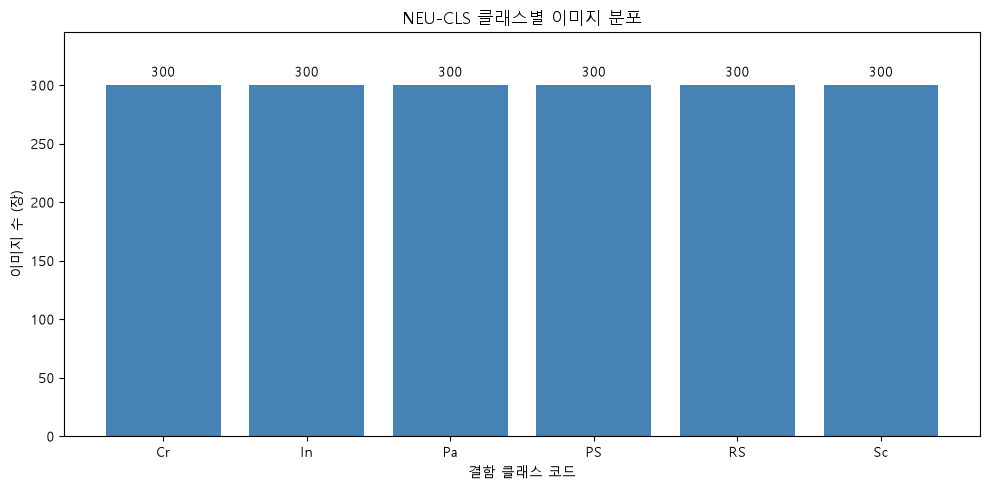

In [2]:
# 클래스별 이미지 개수와 전체 대비 비율을 표로 정리함
class_distribution_eda = pd.DataFrame({
    "코드": list(class_labels_eda),
    "클래스": list(class_labels_eda.values()),
    "이미지 수": [len(paths) for paths in class_images_eda.values()],
})
class_distribution_eda["비율 (%)"] = (
    class_distribution_eda["이미지 수"] / class_distribution_eda["이미지 수"].sum() * 100
).round(2)
display(class_distribution_eda)

# 실제 집계값으로 클래스 균형 여부를 출력함
print("총 이미지 수:", class_distribution_eda["이미지 수"].sum())
print("클래스별 이미지 수 동일:", class_distribution_eda["이미지 수"].nunique() == 1)

# 클래스별 막대를 그린 뒤 막대 위에 이미지 수 표시함
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(class_distribution_eda["코드"], class_distribution_eda["이미지 수"], color="steelblue")
ax.bar_label(bars, padding=4)
ax.set(title="NEU-CLS 클래스별 이미지 분포", xlabel="결함 클래스 코드", ylabel="이미지 수 (장)")
ax.set_ylim(0, class_distribution_eda["이미지 수"].max() * 1.15)
plt.tight_layout()

# 그래프를 PNG로 저장한 뒤 Notebook에 출력함
plt.savefig(figure_dir_eda / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


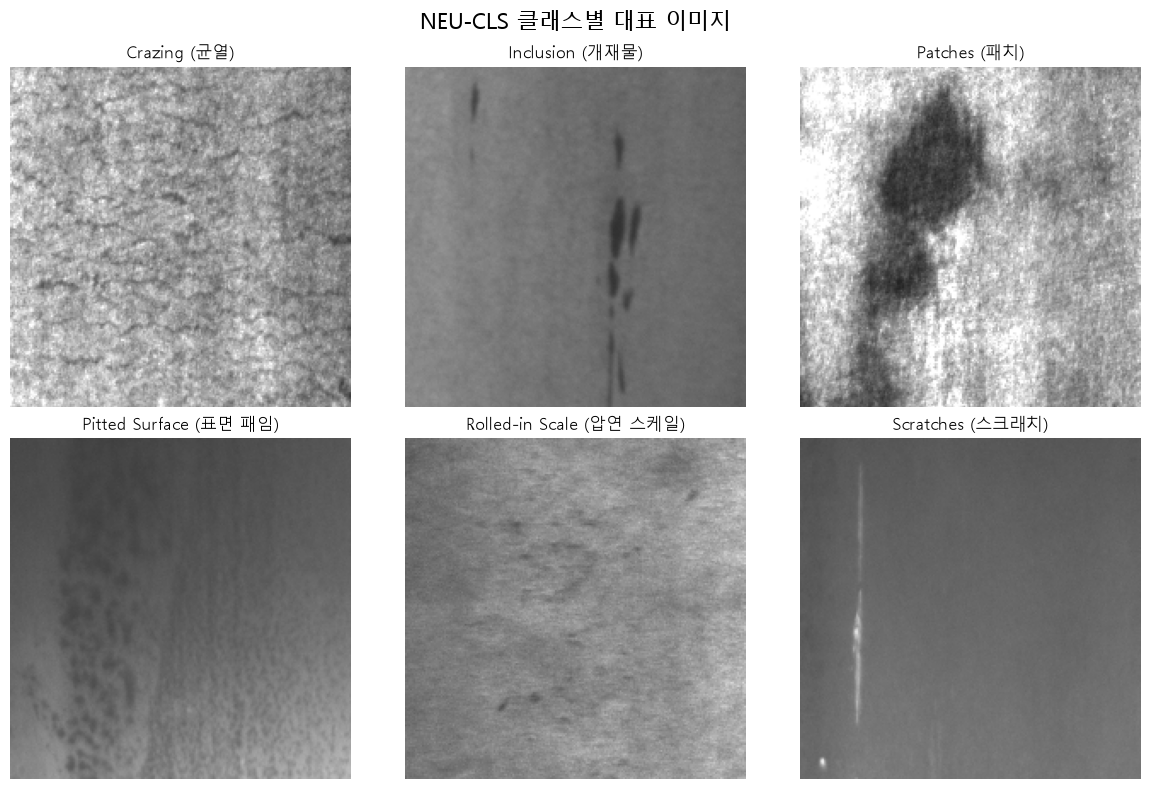

Cr: Cr_1.bmp
In: In_1.bmp
Pa: Pa_1.bmp
PS: PS_1.bmp
RS: RS_1.bmp
Sc: Sc_1.bmp


In [3]:
# 클래스별 첫 번째 이미지를 선택하고 원본 픽셀 배열로 불러옴
sample_paths_eda = {code: paths[0] for code, paths in class_images_eda.items()}
sample_images_eda = {}
for code, path in sample_paths_eda.items():
    with Image.open(path) as image:
        sample_images_eda[code] = np.array(image)

# 2행 3열에서 같은 흑백 밝기 범위와 레이아웃으로 비교함
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (code, image) in zip(axes.flat, sample_images_eda.items()):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(class_labels_eda[code])
    ax.axis("off")
fig.suptitle("NEU-CLS 클래스별 대표 이미지", fontsize=16)
plt.tight_layout()

# 대표 이미지 비교 그래프를 PNG로 저장한 뒤 출력함
plt.savefig(figure_dir_eda / "class_samples.png", dpi=150, bbox_inches="tight")
plt.show()

# 실제 비교에 사용한 이미지 파일명을 출력함
for code, path in sample_paths_eda.items():
    print(f"{code}: {path.name}")


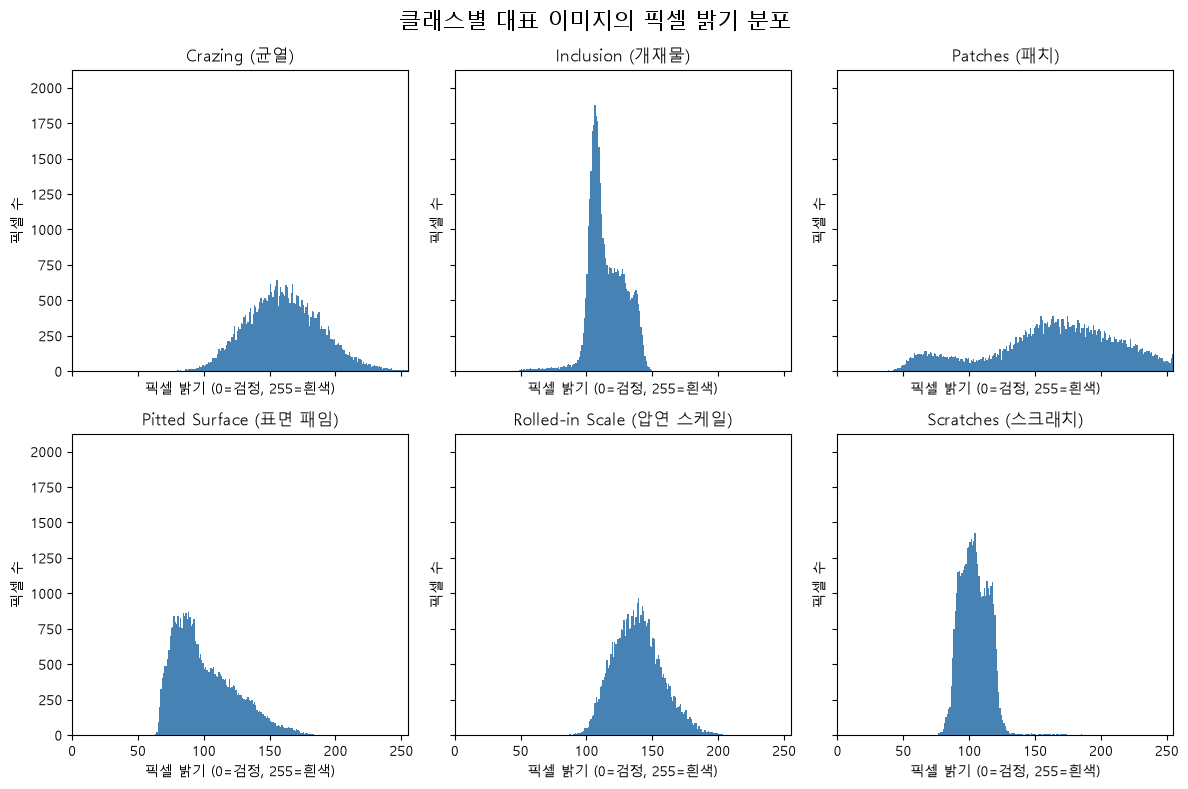

,코드,파일명,최솟값,최댓값,평균 밝기
0,Cr,Cr_1.bmp,60,255,160.58
1,In,In_1.bmp,48,153,114.53
2,Pa,Pa_1.bmp,34,255,166.91
3,PS,PS_1.bmp,63,187,100.20
4,RS,RS_1.bmp,81,217,138.41
5,Sc,Sc_1.bmp,75,241,103.75


In [4]:
# 대표 이미지의 0~255 픽셀 밝기 분포를 같은 축 범위로 비교함
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
for ax, (code, image) in zip(axes.flat, sample_images_eda.items()):
    ax.hist(image.ravel(), bins=256, range=(0, 256), color="steelblue")
    ax.set_title(class_labels_eda[code])
    ax.set(xlabel="픽셀 밝기 (0=검정, 255=흰색)", ylabel="픽셀 수", xlim=(0, 255))
fig.suptitle("클래스별 대표 이미지의 픽셀 밝기 분포", fontsize=16)
plt.tight_layout()

# 밝기 히스토그램을 PNG로 저장한 뒤 출력함
plt.savefig(figure_dir_eda / "pixel_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 선택한 이미지의 밝기 범위와 평균을 표로 정리함
pixel_summary_eda = pd.DataFrame([
    {"코드": code, "파일명": sample_paths_eda[code].name,
     "최솟값": int(image.min()), "최댓값": int(image.max()),
     "평균 밝기": round(float(image.mean()), 2)}
    for code, image in sample_images_eda.items()
])
display(pixel_summary_eda)


### EDA 결과 요약

- **클래스 분포:** 6개 클래스가 각각 300장으로 총 1,800장이며, 클래스별 비율은 약 16.67%로 균형을 이룹니다.
- **선택한 대표 이미지의 결함 형태:** Cr에는 어두운 굽은 선들이 연결된 형태, In에는 세로로 길쭉한 어두운 흔적, Pa에는 넓은 어두운 패치가 보입니다. PS에는 점 형태의 어두운 무늬가 모여 있고, RS에는 불규칙한 어두운 흔적이 흩어져 있으며, Sc에는 가느다란 밝은 세로 선이 보입니다.
- **대표 이미지의 밝기 분포:** Cr은 중간 밝기 이상에 넓게 분포하고, Pa는 낮은 밝기 영역과 높은 밝기 영역이 함께 나타납니다. In은 약 100 부근, PS는 약 80~100 부근, RS는 약 140 부근, Sc는 약 100 부근에 픽셀이 많이 모여 있습니다.
- **평균 밝기:** Cr 160.58, In 114.53, Pa 166.91, PS 100.20, RS 138.41, Sc 103.75입니다. 선택한 이미지 중 Pa의 평균 밝기가 가장 높고 PS가 가장 낮습니다.
- 결함 형태와 밝기 분포에 대한 관찰은 각 클래스의 `_1.bmp` 이미지 1장에 한정되며, 클래스 전체에 대한 결론으로 일반화하지 않습니다.
